# 01 · Risk model on the Azure Predictive Maintenance data

**Question.** For each machine and day: will one of its components fail in the next 7 days?
The app shows that probability as a 0–100 risk score.

**Data.** The Microsoft Azure Predictive Maintenance sample dataset
([Kaggle mirror](https://www.kaggle.com/datasets/arnabbiswas1/microsoft-azure-predictive-maintenance)):
100 machines, hourly telemetry for 2015, error codes, component replacements and **761 component failures**.
Microsoft generated this dataset as a teaching example, so it is not a real factory, but the failure
events are records in the data, not something this project designed. Its license is not clearly stated;
it is used here for an educational, non-commercial demo only.

`training/build_azure_db.py` turns the raw CSVs (not committed) into `maintainai.db`, with **daily** sensor
means instead of hourly readings. This notebook and `training/train_risk_model.py` only read that database,
so everything here can be reproduced from the repository alone.

Steps: look at the data → build daily rows → time-based split → compare models → thresholds and calibration
→ what the model relies on (SHAP).

In [1]:
import sqlite3, sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "training"), str(ROOT / "notebooks")]
import risk_features as rf
import train_risk_model as T
import plot_style as ps

ps.apply()
OUT = ROOT / "results" / "risk_model"
DB = ROOT / "maintainai.db"
with sqlite3.connect(DB) as conn:
    t = rf.load_tables(conn)
{k: len(v) for k, v in t.items()}

{'machines': 100,
 'maintenance': 3279,
 'failures': 761,
 'errors': 3917,
 'sensors': 36500}

## 1. The data

Each failure has a component (comp1–4). Almost every failure (743 of 761) comes with a replacement of that
component on the same day; the remaining replacements are scheduled ones.

In [2]:
f = t["failures"]
pd.DataFrame({
    "failures": f["component"].value_counts(),
    "replacements": t["maintenance"]["component"].value_counts(),
}).sort_index()

,failures,replacements
component,,
comp1,192,802
comp2,259,861
comp3,131,806
comp4,179,810


Failures are not spread evenly: machine model and component age both matter. Below, the average daily
sensor reading around each failure, by failed component (day 0 = failure day). Each component's failure has
its own signature in one sensor, building up over the day or two before. That is why the latest day's
readings carry so much signal, and why a 7-day horizon is ambitious: some failures only show up the day before.

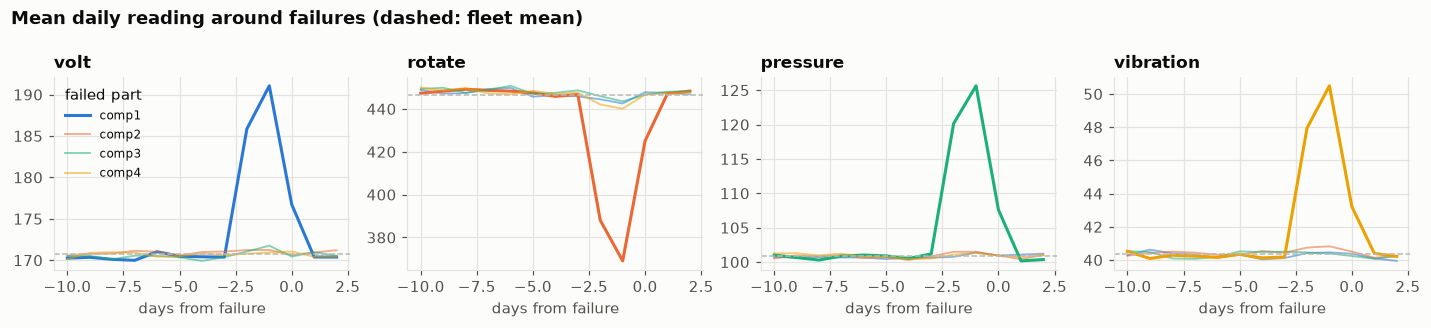

In [3]:
s = t["sensors"].set_index(["machine_id", "date"]).sort_index()
fleet = t["sensors"][rf.SENSORS].mean()
fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharex=True)
for ax, sensor, comp in zip(axes, ["volt", "rotate", "pressure", "vibration"], rf.COMPONENTS):
    for c, color in zip(rf.COMPONENTS, ps.SERIES):
        ev = f[f["component"] == c]
        prof = []
        for k in range(-10, 3):
            idx = list(zip(ev["machine_id"], ev["date"] + pd.Timedelta(days=k)))
            prof.append(s.reindex(idx)[sensor].mean())
        ax.plot(range(-10, 3), prof, color=color, label=c, lw=2 if c == comp else 1.2,
                alpha=1 if c == comp else .55)
    ax.axhline(fleet[sensor], color=ps.NEUTRAL, lw=1, ls="--")
    ax.set_title(sensor)
    ax.set_xlabel("days from failure")
axes[0].legend(title="failed part", fontsize=8)
fig.suptitle("Mean daily reading around failures (dashed: fleet mean)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
ps.save(fig, OUT / "failure_signatures.png")

## 2. Daily rows and labels

One row per machine per day, from 7 January (first full 7-day window) to 24 December 2015 (last day whose
7-day look-ahead is complete). Features use only records up to that day (`risk_features.daily_features`);
the label is 1 if the machine has a failure in the next 7 days.

In [4]:
df = T.build_dataset(DB)
print(f"{len(df):,} rows, {df['machine_id'].nunique()} machines, {df[T.LABEL].mean():.1%} positive")
df[rf.FEATURES].describe().T[["mean", "min", "50%", "max"]].round(1)

35,200 rows, 100 machines, 13.4% positive


,mean,min,50%,max
age_years,11.3,0.0,12.0,20.0
model_no,2.8,1.0,3.0,4.0
days_since_comp1,52.4,0.0,32.0,491.0
days_since_comp2,50.1,0.0,29.0,348.0
days_since_comp3,51.4,0.0,31.0,370.0
days_since_comp4,52.5,0.0,31.0,394.0
volt,170.8,157.8,170.2,218.3
rotate,446.6,271.2,449.2,493.4
pressure,100.8,91.0,100.1,152.3
vibration,40.4,36.2,40.1,61.1


## 3. Time-based split, model comparison

Train on January–August, pick the model on September–October (validation), test once on November–December.
The 7 days before each boundary are dropped from the earlier block because their labels look into the next
one. A random row split would put neighbouring days of the same machine on both sides and flatter the model.

Candidates: always predict the failure rate (baseline), logistic regression, a Random Forest and
gradient boosting (small grids for the last two). PR-AUC is the main metric because only ~13% of rows are positive.

In [5]:
report = T.evaluate(df, t)
res = pd.DataFrame(report["results"]).set_index("model")
print("selected on validation:", report["selected"])
res[["val_pr_auc", "pr_auc", "roc_auc", "brier", "precision_critical", "recall_critical",
     "precision_warning", "recall_warning"]]

selected on validation: {'model': 'Random Forest', 'params': {'max_features': 0.33, 'min_samples_leaf': 10, 'n_estimators': 100}, 'selection': 'validation PR-AUC'}


,val_pr_auc,pr_auc,roc_auc,brier,precision_critical,recall_critical,precision_warning,recall_warning
model,,,,,,,,
Baseline (failure rate),0.125,0.126,0.500,0.1102,NaN,0.000,NaN,0.000
Logistic regression,0.293,0.293,0.689,0.1016,0.545,0.044,0.325,0.356
Random Forest,0.633,0.630,0.909,0.0715,0.743,0.331,0.386,0.822
Gradient boosting,0.614,0.628,0.913,0.0706,0.732,0.390,0.397,0.788


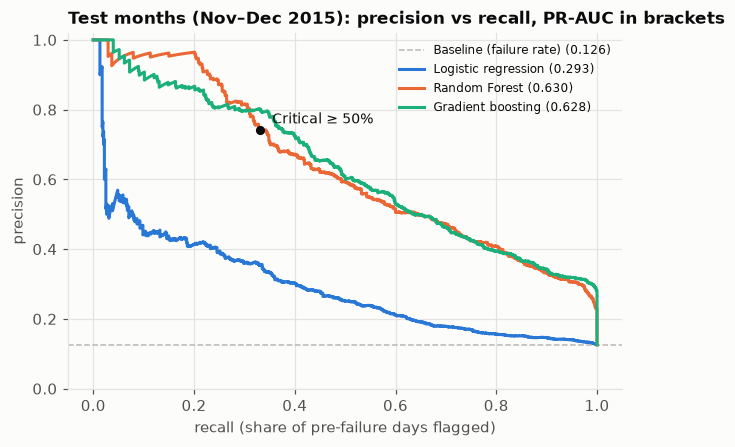

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
y = report["_y_test"]
for (name, p), color in zip(report["_p_test"].items(), [ps.NEUTRAL] + ps.SERIES):
    if name.startswith("Baseline"):
        ax.axhline(y.mean(), color=color, ls="--", lw=1, label=f"{name} ({y.mean():.3f})")
        continue
    prec, rec, _ = precision_recall_curve(y, p)
    ax.plot(rec, prec, color=color, label=f"{name} ({res.at[name, 'pr_auc']:.3f})")
crit = report["test_alerts"]["critical"]
ax.scatter([crit["recall"]], [crit["precision"]], color=ps.TEXT, zorder=5, s=25)
ax.annotate(f"Critical ≥ {report['thresholds']['critical']}%", (crit["recall"], crit["precision"]),
            xytext=(8, 4), textcoords="offset points", fontsize=9)
ax.set(xlabel="recall (share of pre-failure days flagged)", ylabel="precision", ylim=(0, 1.02),
       title="Test months (Nov–Dec 2015): precision vs recall, PR-AUC in brackets")
ax.legend(fontsize=8, loc="upper right")
ps.save(fig, OUT / "pr_curves.png")

Logistic regression is far behind: the relationships are not linear (a component is risky when it is
old *and* its sensor drifts). The forest and gradient boosting are close on test; the forest was picked
because it won on validation, and it has another advantage here: its probabilities average many trees, so
SHAP values come out directly in percentage points of risk.

## 4. Thresholds and calibration

Both are set on validation. Critical = 50% (a failure in the next week is more likely than not). Warning =
the highest multiple of 5 that still flags 80% of the days before a failure.

In [7]:
pd.DataFrame({**{f"validation {k}": v for k, v in report["threshold_choice"]["validation"].items()},
              **{f"test {k}": v for k, v in report["test_alerts"].items()}}).T

,threshold,flagged,true_alarms,false_alarms,precision,recall
validation warning,20.0,1621.0,614.0,1007.0,0.379,0.805
validation critical,50.0,375.0,278.0,97.0,0.741,0.364
test warning,20.0,1449.0,559.0,890.0,0.386,0.822
test critical,50.0,303.0,225.0,78.0,0.743,0.331


In [8]:
pd.DataFrame(report["test_failure_events"]).T

,events,caught,lead_days_median,caught_2plus_days_ahead,first,last
warning,111,108,7.0,105,2015-11-02,2015-12-31
critical,111,100,2.0,93,2015-11-02,2015-12-31


Counted per failure event, the Critical alerts are useful: most failures have at least one Critical day in
the week before. The median warning is only about two days, though: the forest mostly reacts to the sensor
drift that starts shortly before a failure, so this is an early-warning signal, not a long-range forecast.

**Calibration.** If the scores are probabilities, a group of machine-days scored ~30% should fail about 30% of
the time.

{'validation_ece': 0.022, 'max_ece': 0.05, 'calibrated': False, 'test_brier_raw_train_only': 0.0725, 'test_brier_isotonic_train_only': 0.0719, 'test_ece': 0.018}


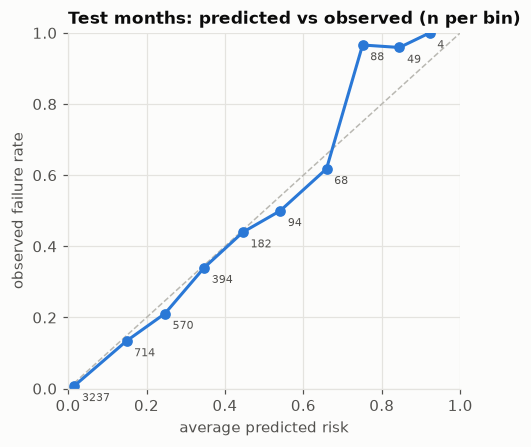

In [9]:
cal = report["calibration"]
print({k: v for k, v in cal.items() if k != "test_reliability"})
rel = pd.DataFrame(cal["test_reliability"])
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, 1], [0, 1], color=ps.NEUTRAL, ls="--", lw=1)
ax.plot(rel["predicted"], rel["observed"], marker="o", color=ps.SERIES[0])
for _, r in rel.iterrows():
    ax.annotate(f"{int(r['n'])}", (r["predicted"], r["observed"]), xytext=(5, -10),
                textcoords="offset points", fontsize=7, color=ps.TEXT_2)
ax.set(xlabel="average predicted risk", ylabel="observed failure rate", xlim=(0, 1), ylim=(0, 1),
       title="Test months: predicted vs observed (n per bin)")
ps.save(fig, OUT / "reliability.png")

Close to the diagonal: validation ECE is about 0.02, below the 0.05 limit set in advance, and isotonic
calibration barely changes the test Brier score. So no calibration step is added, which keeps the SHAP
values exact (they add up to the score the user sees).

## 5. What the model relies on (SHAP)

The app's model is the same setting refit on every labelled day (`risk_model.pkl`). SHAP values below are
computed on 1,500 machine-days sampled from the test months.

In [10]:
import shap
bundle = joblib.load(ROOT / "risk_model.pkl")
X = df[df["date"] >= T.TEST_START][rf.FEATURES].sample(1500, random_state=0)
sv = shap.TreeExplainer(bundle["model"]).shap_values(X)
sv = np.asarray(sv)[..., 1] * 100  # failure class, in percentage points
imp = pd.Series(np.abs(sv).mean(axis=0), index=rf.FEATURES).sort_values(ascending=False)
imp.round(2)

C:\Users\mam83\OneDrive\Documents\MaintainAI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


days_since_comp2    4.04
days_since_comp3    3.63
days_since_comp4    3.62
days_since_comp1    3.14
model_no            2.84
age_years           2.36
rotate              1.93
volt                1.24
vibration           0.90
pressure            0.61
pressure_7d         0.50
errors_7d           0.44
volt_7d             0.41
rotate_7d           0.39
vibration_7d        0.33
dtype: float64

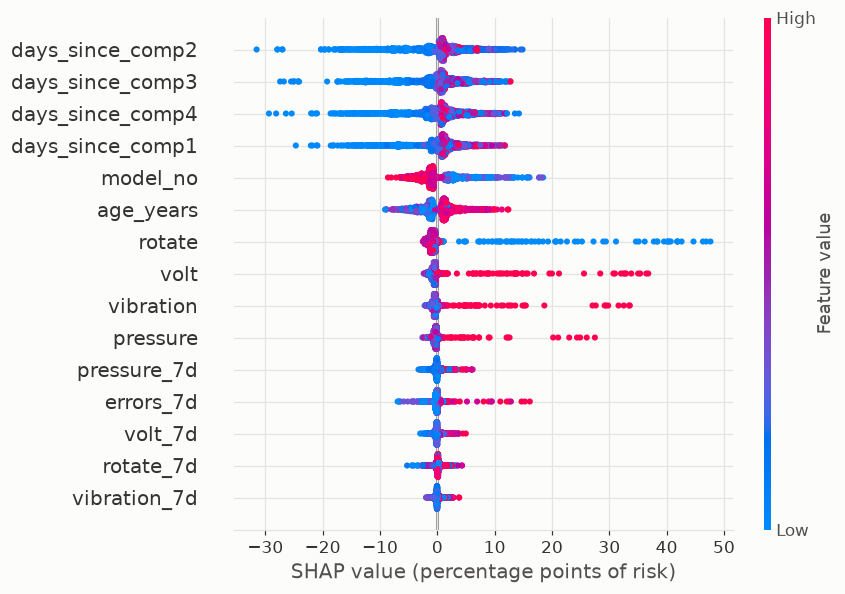

In [11]:
shap.summary_plot(sv, X, show=False, max_display=15, plot_size=(8, 5.5))
fig = plt.gcf()
fig.axes[0].set_xlabel("SHAP value (percentage points of risk)")
ps.save(fig, OUT / "shap_summary.png")

Reading it:
- **Component ages** (`days_since_comp*`) carry the most weight: in this dataset a part that has run a long time
  since its last replacement is more likely to fail.
- **Machine model and age** come next: model1 and model2 machines fail more often per machine than model3 and model4.
- **Latest-day sensor readings** matter more than the 7-day means: the failure signatures above build up in the last day or two.
- Error codes add a little on top of the sensors they echo.

SHAP explains the model, not the machines: these are associations learned from one simulated year.

## 6. Summary

- Target: failure of any component within 7 days, per machine-day (13% positive).
- Time-based split with a 7-day gap; model chosen on validation; test touched once.
- Random Forest, test PR-AUC ≈ 0.63 vs 0.13 for the baseline.
- Critical (≥ 50%): roughly 3 in 4 Critical days are followed by a failure, and about 9 in 10 failures had a Critical
  alert in the week before, but the median lead time is only about 2 days.
- Probabilities are well calibrated without a calibration step.
- Limits: one year of generated data, 100 machines, failures that announce themselves through clean sensor
  signatures. Real plants are messier; this is a demonstration of the method, not a performance claim.